# P2.16 — Vacant dwellings against housing pressure

**Question:** RQ2.5 (how many vacant dwellings could realistically return to residential use?). Companion of `p2_05` (supply
against households) and `p2_06` (second homes).

The census counts vacant conventional dwellings per municipality (2011, 2021) but not their condition, owner, price or whether they
are for sale or rent. So "realistically" is bounded by two things the data do show. (1) Only vacancy above a frictional level counts:
homes between tenants, being sold, inherited or repaired are vacant in any market (assumed 5% of the stock, with 3% and 8% as checks).
(2) A vacant home cannot be moved: it helps only where households are short. The shortfall of a municipality is its implied new
households of 2021-2023 minus its completions (the `p2_05` proxy), floored at zero, and what its excess vacancy could house is the
smaller of the two. How much of the excess is habitable and worth repairing is not in the data, so it is varied, not assumed.

In [1]:
import pandas as pd
from scipy import stats

from pthousing.analysis import supply, vacancy
from pthousing.config import FRICTIONAL_VACANCY_PCT, PROCESSED
from pthousing.data import typology
from pthousing.viz import charts, style

style.apply_style()
panel = pd.read_parquet(PROCESSED / "panel_municipality_year.parquet")
stock = supply.read_stock()
ty = typology.read().set_index("muni_code")
bal = supply.balance(panel, stock)
tab = vacancy.table(stock)
short = vacancy.shortfall(bal)
tab["excess_2021_n"] = vacancy.excess(tab["vacant_2021_n"], tab["dwellings_2021_n"])

## Step 1 — How many are vacant, and where
Vacant dwellings barely moved between the censuses, but they left the cities and gathered in the countryside.

In [2]:
national = pd.DataFrame(
    {
        year: {
            "dwellings_n": tab[f"dwellings_{year}_n"].sum(),
            "vacant_n": tab[f"vacant_{year}_n"].sum(),
        }
        for year in (2011, 2021)
    }
).T
national["vacancy_pct"] = 100 * national["vacant_n"] / national["dwellings_n"]
print(national.round(1).to_string())

by_density = vacancy.by_group(tab, short, ty["density_class"]).loc[
    ["urban", "intermediate", "rural"]
]
by_density["vacant_change_n"] = by_density["vacant_2021_n"] - by_density["vacant_2011_n"]
by_coast = vacancy.by_group(tab, short, ty["coast_class"])
cols = ["vacancy_2011_pct", "vacancy_2021_pct", "vacant_change_n", "excess_n", "shortfall_n"]
style.save_table(by_density[cols].round(1).reset_index(), "p2", "vacancy_by_density")
by_density[cols].round(1)

      dwellings_n  vacant_n  vacancy_pct
2011      5859540    735128         12.5
2021      5970677    723215         12.1


,vacancy_2011_pct,vacancy_2021_pct,vacant_change_n,excess_n,shortfall_n
density_class,,,,,
urban,12.3,10.4,-41602,129746.2,106562.1
intermediate,12.5,12.2,1360,141955.8,62901.7
rural,13.0,14.6,28329,152979.0,25961.6


## Step 2 — Is vacancy where prices are high?
Municipalities in terciles of 2024 price-to-income. Vacancy is highest where prices are lowest: the association is negative.

In [3]:
pti = panel[panel["year"] == 2024].set_index("muni_code")["pti_years"].dropna()
tercile = pd.qcut(pti, 3, labels=["low", "middle", "high"])
rho, p = stats.spearmanr(tab.loc[pti.index, "vacancy_2021_pct"], pti)
groups = vacancy.by_group(tab.loc[pti.index], short, tercile)
groups["vacancy_change_pp"] = groups["vacancy_2021_pct"] - groups["vacancy_2011_pct"]
gcols = [
    "vacancy_2011_pct",
    "vacancy_2021_pct",
    "vacancy_change_pp",
    "excess_n",
    "shortfall_n",
    "covered_n",
    "coverage_pct",
]
style.save_table(
    groups[gcols].round(1).reset_index(names="price_to_income"), "p2", "vacancy_by_price_pressure"
)
print(f"Spearman, vacancy rate 2021 vs price-to-income 2024: {rho:+.2f} (p {p:.3g}, n {len(pti)})")
groups[gcols].round(1)

Spearman, vacancy rate 2021 vs price-to-income 2024: -0.39 (p 4.93e-12, n 299)


,vacancy_2011_pct,vacancy_2021_pct,vacancy_change_pp,excess_n,shortfall_n,covered_n,coverage_pct
pti_years,,,,,,,
low,12.8,15.2,2.4,71755.0,5376.6,5372.8,99.9
middle,13.1,13.9,0.7,110047.2,26108.9,26108.9,100.0
high,12.3,11.0,-1.3,241032.6,163899.1,142947.3,87.2


## Step 3 — Excess vacancy against the shortfall, municipality by municipality
In total there is more excess vacancy than shortfall, but the largest shortfalls are in the suburbs of Lisboa and Porto, where
vacancy is lowest. The right panel lists them.

,name,vacancy_2021_pct,vacant_2021_n,excess_n,shortfall_n,coverage_pct
muni_code,,,,,,
1106,Lisboa,14.9,47748,31766.0,19144.5,100.0
1111,Sintra,9.3,17035,7830.2,11777.8,66.5
1312,Porto,15.2,20270,13602.4,7505.0,100.0
1115,Amadora,9.3,8101,3743.8,7247.4,51.7
1107,Loures,10.3,10126,5233.6,6792.5,77.0
1116,Odivelas,8.7,6267,2672.8,6499.4,41.1
1510,Seixal,8.0,6673,2527.6,5778.8,43.7
1503,Almada,8.6,8779,3703.0,5294.4,69.9
1105,Cascais,10.1,11197,5669.4,4919.5,100.0


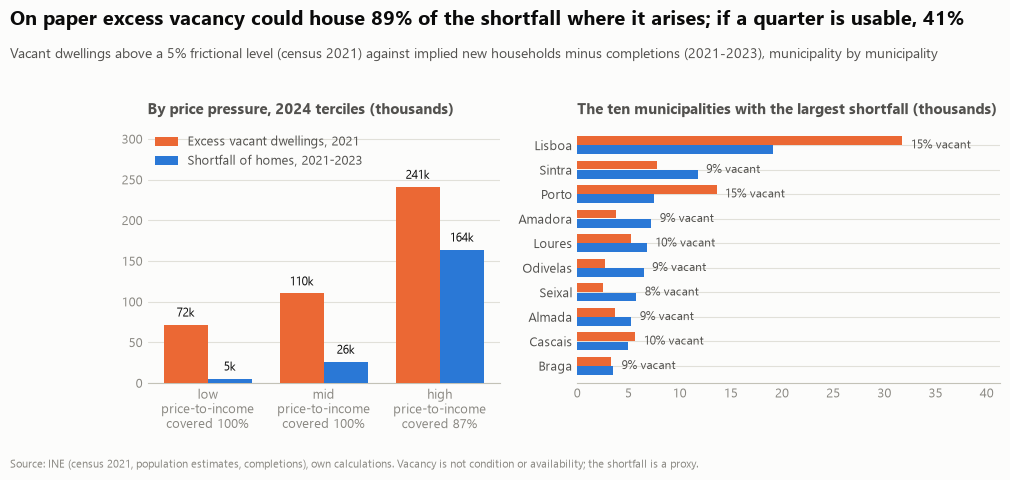

In [4]:
names = ty["muni_name"]
top = vacancy.largest_shortfalls(tab, short, names)
sens = vacancy.sensitivity(tab, short)
fig = charts.vacancy_vs_shortfall(groups.rename(index={"middle": "mid"}), top, sens)
style.save_fig(fig, "p2", "vacancy_vs_shortfall")
style.save_table(top.round(1).reset_index(), "p2", "vacancy_largest_shortfalls")
top.round(1)

## Step 4 — How much would have to be usable?
Coverage of the shortfall by frictional level and by the share of the excess that is habitable, for sale or let and worth repairing.
The last column asks the opposite question: the usable share at which local coverage reaches half and three quarters.

In [5]:
style.save_table(sens.round(2), "p2", "vacancy_sensitivity")
needed = (
    pd.DataFrame(
        {
            pct: {
                target: vacancy.usable_share_for(
                    target,
                    vacancy.excess(tab["vacant_2021_n"], tab["dwellings_2021_n"], pct),
                    short,
                )
                for target in (50, 75)
            }
            for pct in (3.0, 5.0, 8.0)
        }
    )
    .T.rename_axis("frictional_pct")
    .rename(columns=lambda t: f"usable_share_for_{t}pct")
)
style.save_table(needed.round(3).reset_index(), "p2", "vacancy_usable_share_needed")
print(
    sens.pivot(index="frictional_pct", columns="usable_share", values="coverage_pct")
    .round(0)
    .to_string()
)
needed.round(2)

usable_share    0.25  0.50  1.00
frictional_pct                  
3.0             51.0  80.0  97.0
5.0             41.0  67.0  89.0
8.0             24.0  41.0  62.0


,usable_share_for_50pct,usable_share_for_75pct
frictional_pct,,
3.0,0.24,0.45
5.0,0.33,0.60
8.0,0.68,NaN


## Key numbers

In [6]:
n = national
print(
    f"vacant dwellings {n.loc[2011, 'vacant_n']:,.0f} ({n.loc[2011, 'vacancy_pct']:.1f}%) -> {n.loc[2021, 'vacant_n']:,.0f} ({n.loc[2021, 'vacancy_pct']:.1f}%)"
)
for name, r in by_density.iterrows():
    print(
        f"  {name}: vacancy {r.vacancy_2011_pct:.1f}% -> {r.vacancy_2021_pct:.1f}%, vacant {r.vacant_change_n:+,.0f}, excess {r.excess_n:,.0f}, shortfall {r.shortfall_n:,.0f}, n {int(r.municipalities_n)}"
    )
default = sens[
    (sens["frictional_pct"] == FRICTIONAL_VACANCY_PCT) & (sens["usable_share"] == 1.0)
].iloc[0]
print(
    f"excess vacancy at {FRICTIONAL_VACANCY_PCT:.0f}%: {default.excess_n:,.0f}; shortfall {default.shortfall_n:,.0f}; "
    f"covered locally {default.covered_n:,.0f} ({default.coverage_pct:.0f}%)"
)
for name, r in groups.iterrows():
    print(
        f"  price-to-income {name}: vacancy {r.vacancy_2021_pct:.1f}% ({r.vacancy_change_pp:+.1f} pp), excess {r.excess_n:,.0f}, shortfall {r.shortfall_n:,.0f}, covered {r.coverage_pct:.0f}%"
    )
print(
    f"municipalities with excess below shortfall: {(tab['excess_2021_n'] < short).sum()} of {short.gt(0).sum()} with a shortfall; "
    f"top ten hold {100 * top['shortfall_n'].sum() / short.sum():.0f}% of the shortfall, covering {100 * (top[['excess_n', 'shortfall_n']].min(axis=1).sum()) / top['shortfall_n'].sum():.0f}% of it"
)
print(
    f"usable share needed (5%): half {needed.loc[5.0].iloc[0]:.2f}, three quarters {needed.loc[5.0].iloc[1]:.2f}"
)

vacant dwellings 735,128 (12.5%) -> 723,215 (12.1%)
  urban: vacancy 12.3% -> 10.4%, vacant -41,602, excess 129,746, shortfall 106,562, n 35
  intermediate: vacancy 12.5% -> 12.2%, vacant +1,360, excess 141,956, shortfall 62,902, n 84
  rural: vacancy 13.0% -> 14.6%, vacant +28,329, excess 152,979, shortfall 25,962, n 189
excess vacancy at 5%: 424,681; shortfall 195,425; covered locally 174,470 (89%)
  price-to-income low: vacancy 15.2% (+2.4 pp), excess 71,755, shortfall 5,377, covered 100%
  price-to-income middle: vacancy 13.9% (+0.7 pp), excess 110,047, shortfall 26,109, covered 100%
  price-to-income high: vacancy 11.0% (-1.3 pp), excess 241,033, shortfall 163,899, covered 87%
municipalities with excess below shortfall: 18 of 237 with a shortfall; top ten hold 40% of the shortfall, covering 77% of it
usable share needed (5%): half 0.33, three quarters 0.60
